# EMOT -- results walkthrough

A guided read of the committed benchmark (`results/`). Every table and figure is computed from the JSON files; nothing is typed by hand. For the full write-up see `docs/results.md` and `docs/edge.md`.

In [1]:
import json, warnings
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import Image, display
from emot.benchmark.aggregate import (load_tracking_results, load_detection_results, load_edge_benchmark,
                                      sequence_table, mean_by_tracker)
from emot.benchmark.replay import VARIANTS
warnings.filterwarnings('ignore'); pd.set_option('display.width', 160)
ROOT = Path('..') if Path('../results').exists() else Path('.')
trk = load_tracking_results(ROOT / 'results'); det = load_detection_results(ROOT / 'results')
seq = sequence_table(ROOT / 'results'); edge = pd.DataFrame(load_edge_benchmark(ROOT / 'results')['rows'])
print(len(trk), 'tracking runs |', trk.sequence.nunique(), 'sequences |', trk.backbone.nunique(), 'backbones |', trk.tracker.nunique(), 'trackers')

294 tracking runs | 7 sequences | 6 backbones | 7 trackers


## 1. The data: 7 MOT17 sequences, split by *measured* camera motion

The `camera` column comes from the optical-flow estimator, not from the dataset's description.

In [2]:
seq[['sequence','width','height','fps','frames','gt_tracks','mean_people_per_frame','camera_motion_px','camera']]

,sequence,width,height,fps,frames,gt_tracks,mean_people_per_frame,camera_motion_px,camera
0,MOT17-02,1920,1080,30,600,62,31.0,0.21,static
1,MOT17-04,1920,1080,30,1050,83,45.3,0.21,static
2,MOT17-05,640,480,14,837,133,8.3,5.42,moving
3,MOT17-09,1920,1080,30,525,26,10.1,0.41,static
4,MOT17-10,1920,1080,30,654,57,19.6,4.96,moving
5,MOT17-11,1920,1080,30,900,75,10.5,4.84,moving
6,MOT17-13,1920,1080,25,750,110,15.5,12.73,moving


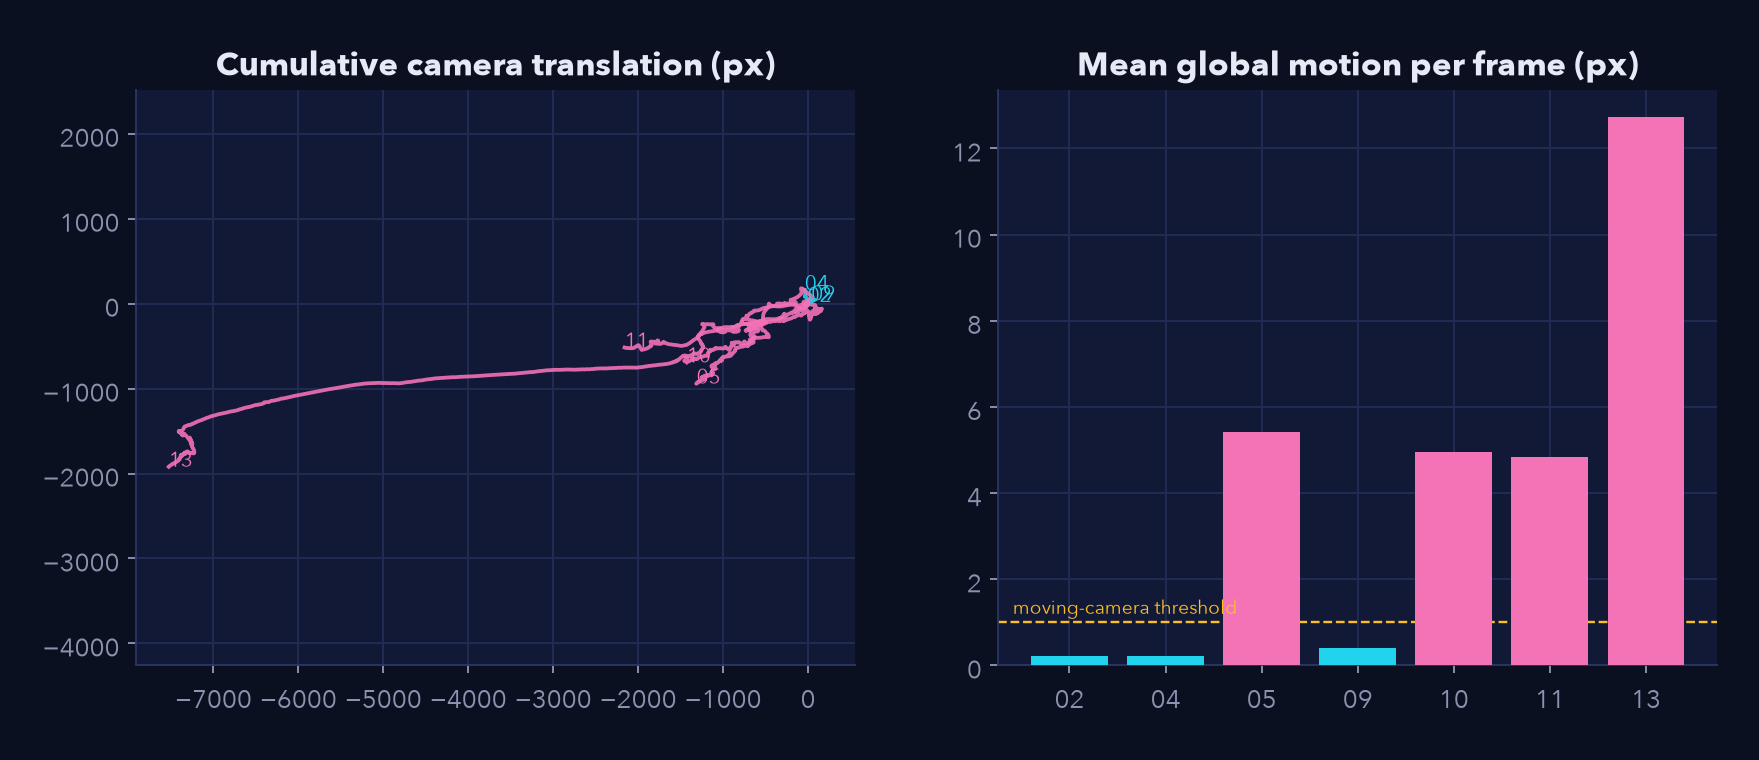

In [3]:
display(Image(ROOT / 'docs/figures/camera_motion.png', width=900))

## 2. The leaderboard

Mean over all sequences and backbones; detectors are shared, so differences are pure association.

In [4]:
lb = mean_by_tracker(trk).rename(index=lambda t: VARIANTS[t].label)
lb.round(3)

,mota,idf1,hota,deta,assa,loca,num_switches
tracker,,,,,,,
BoT-SORT (CMC + ReID),0.383,0.490,0.403,0.364,0.462,0.817,40.881
BoT-SORT (CMC),0.383,0.478,0.395,0.364,0.444,0.816,44.024
BoT-SORT (ReID only),0.379,0.479,0.394,0.359,0.447,0.816,50.429
DeepSORT (OSNet + cascade),0.353,0.472,0.392,0.369,0.426,0.809,111.643
DeepSORT (OSNet),0.345,0.466,0.387,0.369,0.415,0.809,168.976
ByteTrack,0.379,0.467,0.386,0.359,0.429,0.816,55.905
DeepSORT (ResNet18),0.364,0.414,0.351,0.362,0.355,0.814,139.595


### Held-out check (tuned on MOT17-02, so drop it)

In [5]:
mean_by_tracker(trk, exclude_sequences=('MOT17-02',)).rename(index=lambda t: VARIANTS[t].label).round(3)

,mota,idf1,hota,deta,assa,loca,num_switches
tracker,,,,,,,
BoT-SORT (CMC + ReID),0.413,0.518,0.422,0.390,0.469,0.814,42.111
BoT-SORT (CMC),0.412,0.505,0.414,0.390,0.454,0.814,45.278
DeepSORT (OSNet + cascade),0.380,0.498,0.410,0.392,0.437,0.808,111.694
BoT-SORT (ReID only),0.407,0.504,0.410,0.384,0.451,0.814,53.444
DeepSORT (OSNet),0.371,0.492,0.407,0.393,0.429,0.808,173.389
ByteTrack,0.406,0.492,0.402,0.384,0.436,0.814,59.361
DeepSORT (ResNet18),0.391,0.436,0.367,0.387,0.361,0.812,145.194


## 3. What each component buys

Paired per-(sequence, backbone) comparisons: mean HOTA change and how often the first tracker wins.

In [6]:
cams = dict(zip(seq.sequence, seq.camera))
def paired(a, b, metric='hota', cam=None):
    d = trk if cam is None else trk[trk.sequence.map(cams) == cam]
    pa = d[d.tracker == a].set_index(['sequence','backbone'])[metric]
    pb = d[d.tracker == b].set_index(['sequence','backbone'])[metric]
    diff = (pa - pb).dropna(); return round(diff.mean(), 4), int((diff > 0).sum()), len(diff)
rows = [('CMC vs ByteTrack, moving', *paired('botsort_cmc','bytetrack',cam='moving')),
        ('CMC vs ByteTrack, static', *paired('botsort_cmc','bytetrack',cam='static')),
        ('OSNet vs ResNet18 (DeepSORT)', *paired('deepsort_osnet','deepsort')),
        ('cascade vs single-stage', *paired('deepsort_osnet_cascade','deepsort_osnet')),
        ('BoT-SORT full vs ByteTrack', *paired('botsort','bytetrack'))]
pd.DataFrame(rows, columns=['comparison','mean ΔHOTA','wins','pairs'])

,comparison,mean ΔHOTA,wins,pairs
0,"CMC vs ByteTrack, moving",0.0182,20,24
1,"CMC vs ByteTrack, static",-0.0017,5,18
2,OSNet vs ResNet18 (DeepSORT),0.0360,40,42
3,cascade vs single-stage,0.0048,30,42
4,BoT-SORT full vs ByteTrack,0.0176,34,42


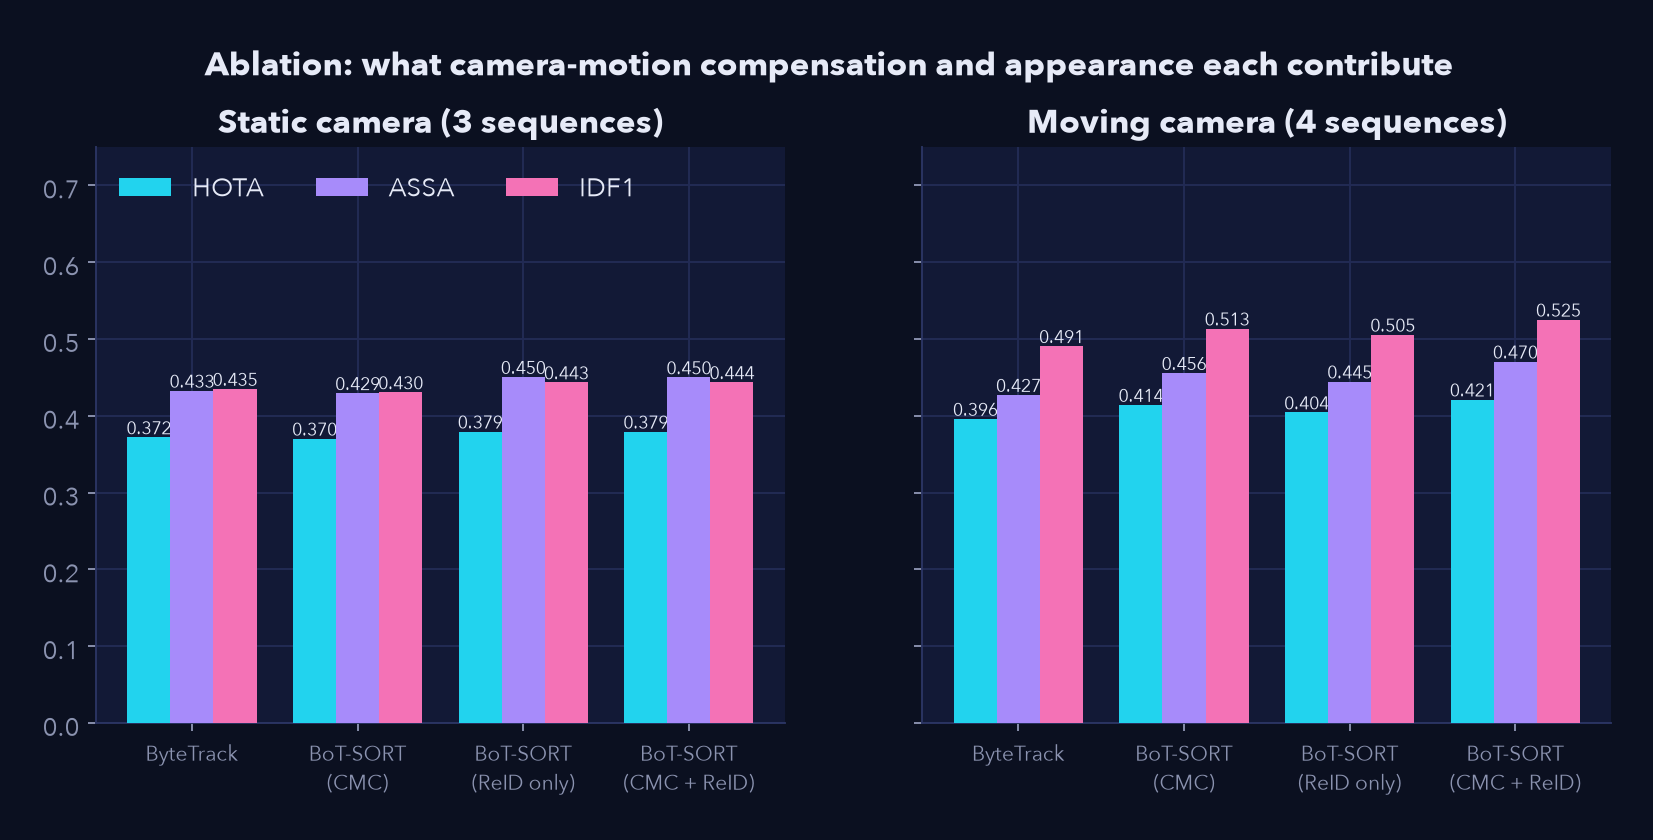

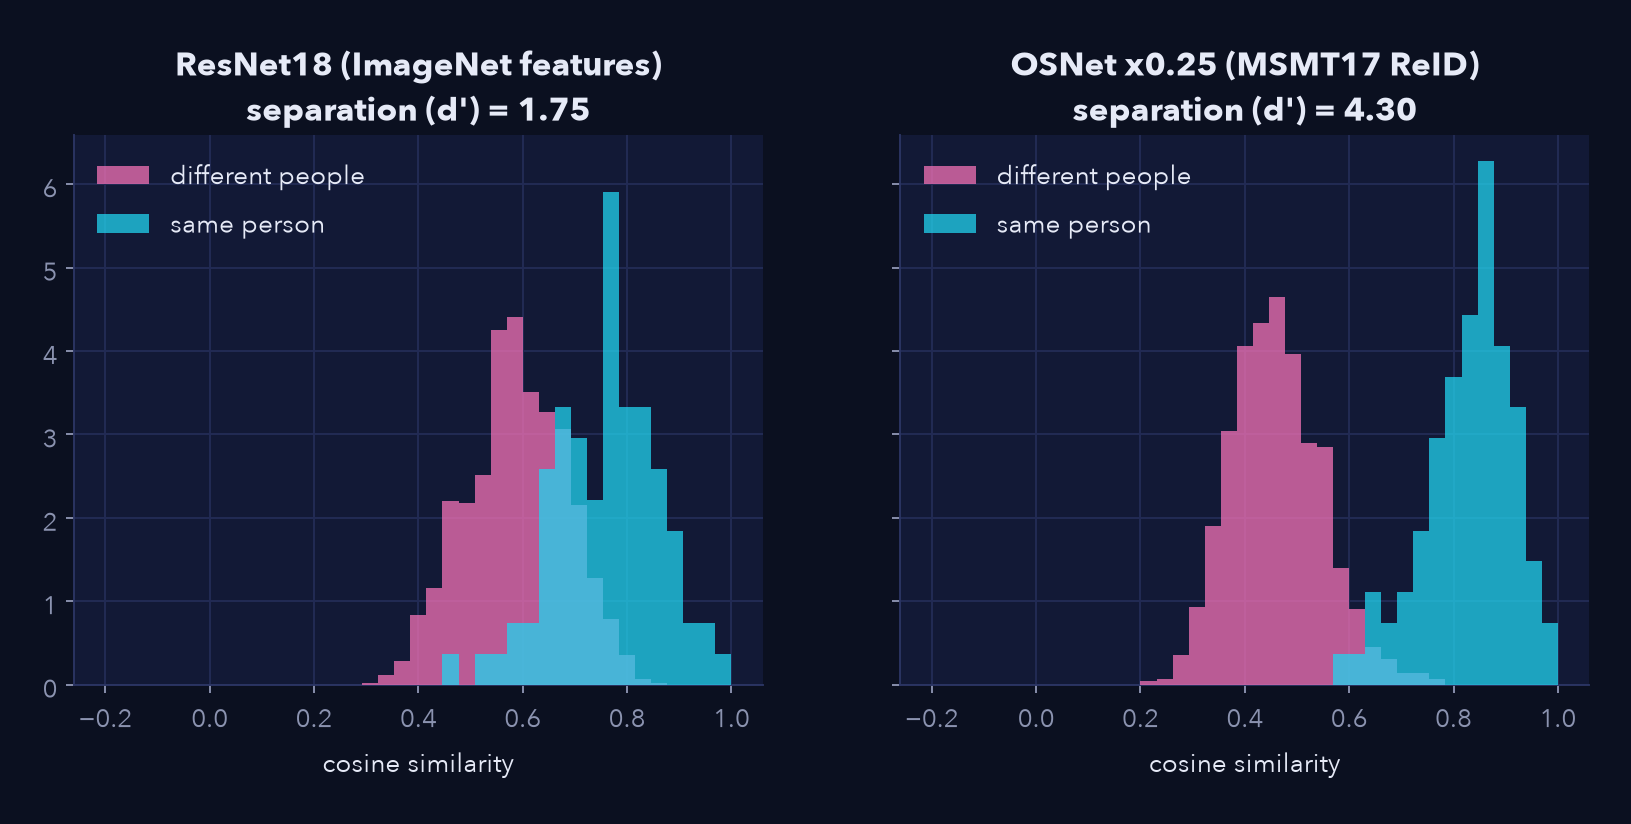

In [7]:
display(Image(ROOT / 'docs/figures/ablation_cmc_reid.png', width=900))
display(Image(ROOT / 'docs/figures/reid_separation.png', width=800))

### Sequences are not independent samples

Six backbones share each of the seven scenes, so a bootstrap over *scenes* is the honest uncertainty estimate. With only 7 scenes it is wide -- read the paired deltas as descriptive.

In [8]:
rng = np.random.default_rng(0)
def scene_deltas(a, b, metric='hota'):
    d = trk.pivot_table(index='sequence', columns='tracker', values=metric)
    return (d[a] - d[b]).values
def boot(x, n=5000): return np.percentile([rng.choice(x, len(x)).mean() for _ in range(n)], [2.5, 97.5])
for a, b in [('botsort','bytetrack'), ('deepsort_osnet','deepsort'), ('botsort_cmc','bytetrack')]:
    x = scene_deltas(a, b); lo, hi = boot(x)
    print(f'{VARIANTS[a].label} - {VARIANTS[b].label}: mean {x.mean():+.3f}, 95% bootstrap CI over scenes [{lo:+.3f}, {hi:+.3f}]')

BoT-SORT (CMC + ReID) - ByteTrack: mean +0.018, 95% bootstrap CI over scenes [+0.007, +0.032]
DeepSORT (OSNet) - DeepSORT (ResNet18): mean +0.036, 95% bootstrap CI over scenes [+0.019, +0.056]
BoT-SORT (CMC) - ByteTrack: mean +0.010, 95% bootstrap CI over scenes [-0.001, +0.022]


## 4. Per-scene view

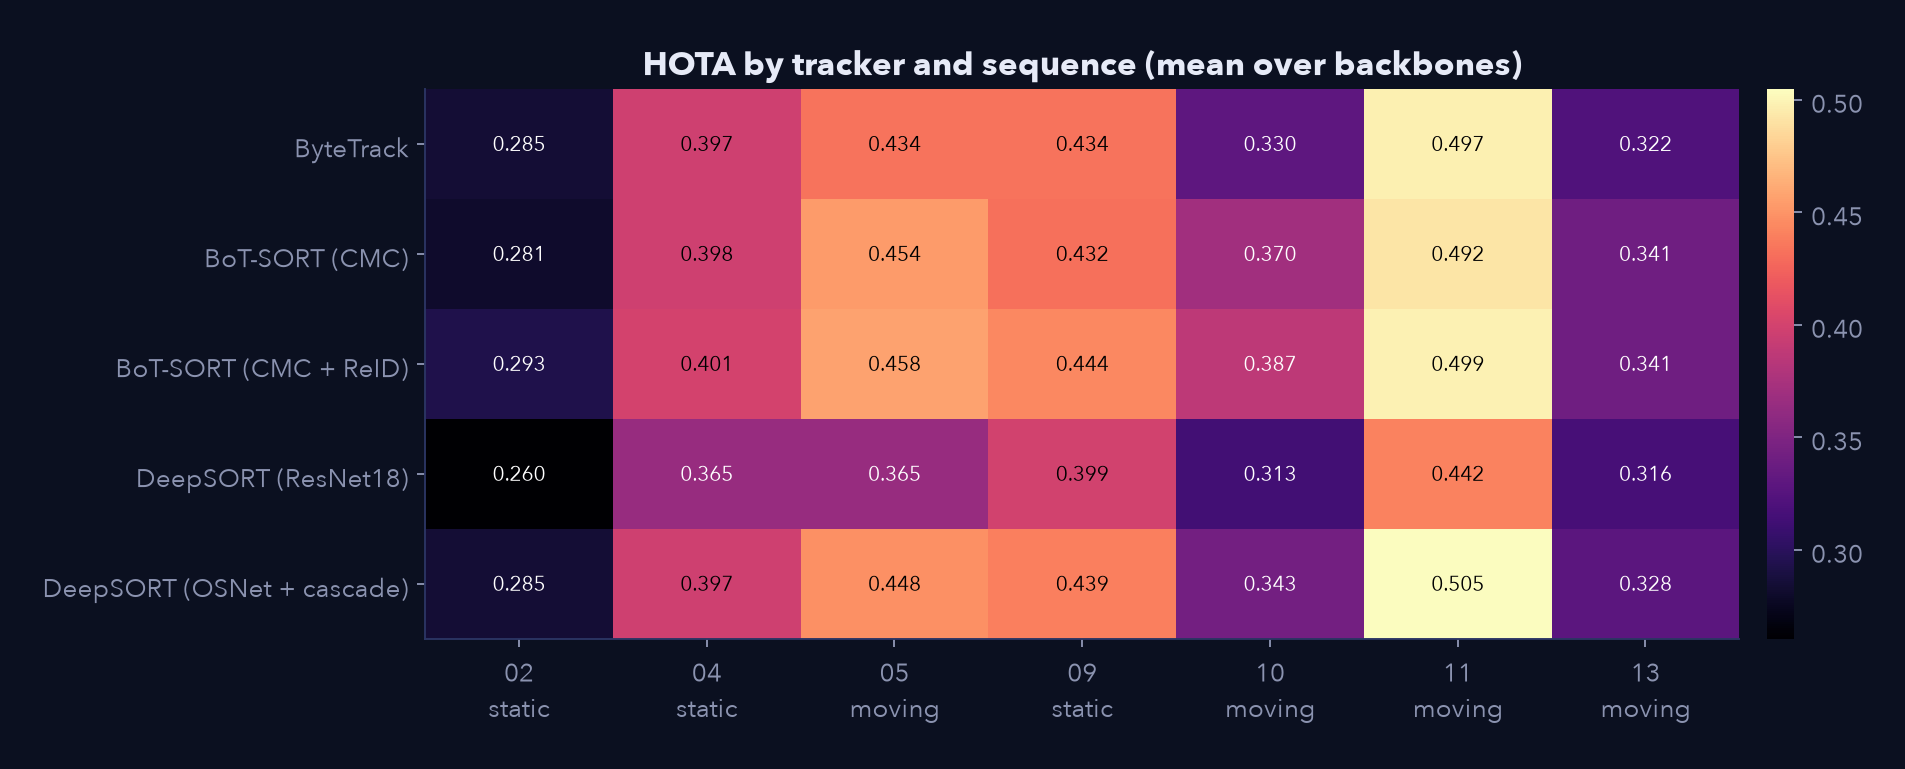

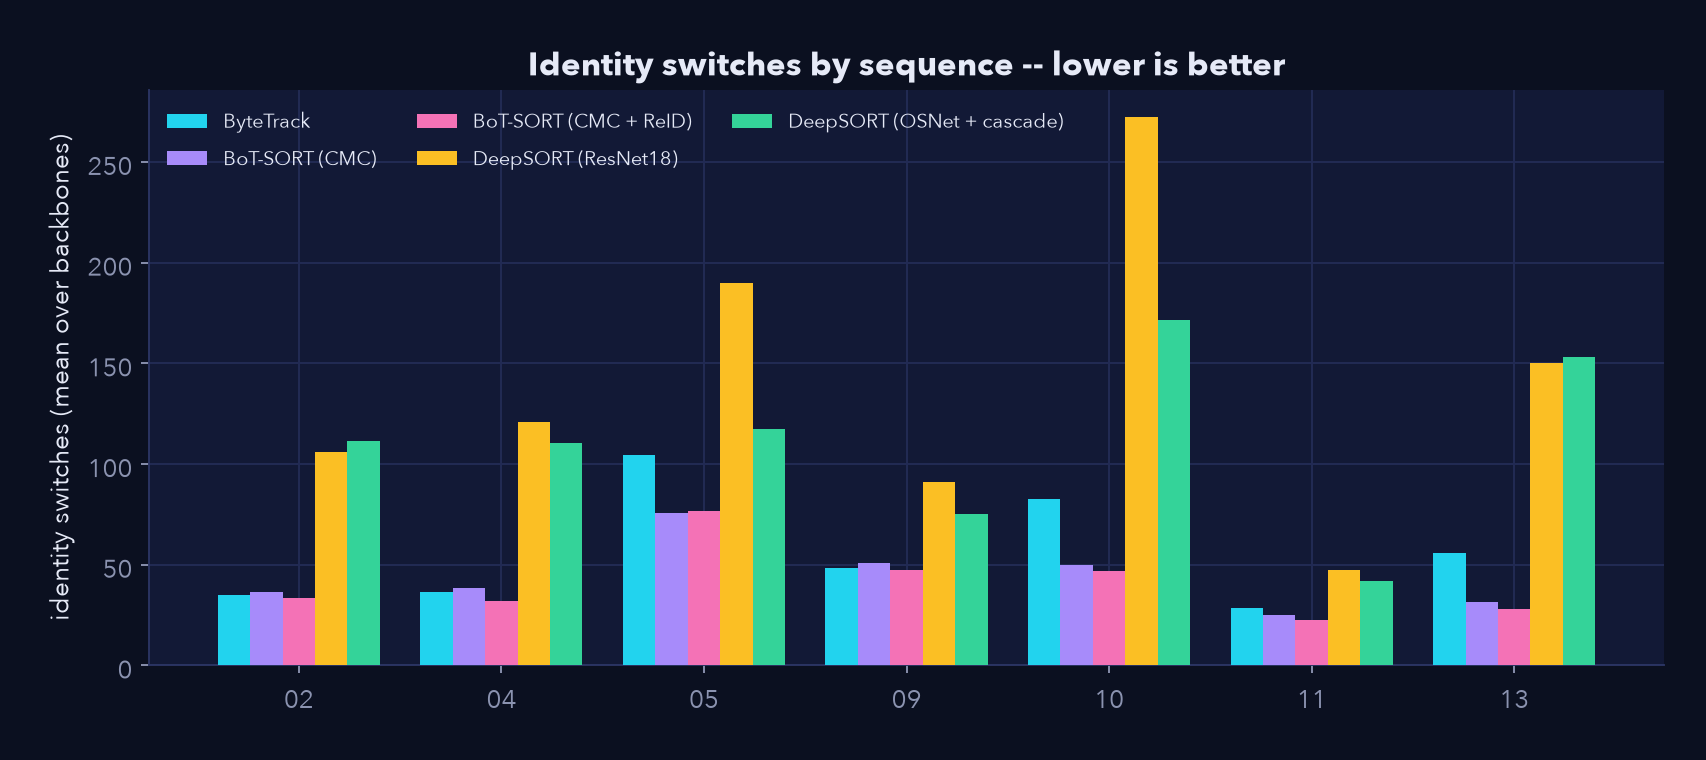

In [9]:
display(Image(ROOT / 'docs/figures/heatmap_hota.png', width=900))
display(Image(ROOT / 'docs/figures/id_switches.png', width=900))

## 5. Detectors and the edge

In [10]:
main = edge[edge.group == 'main']
main.pivot_table(index='backbone', columns='variant', values='mean_ms').round(1)

variant,onnx_coreml,onnx_fp32,onnx_int8_dynamic,onnx_int8_static,onnx_int8_static_fp32head,torch_cpu,torch_mps
backbone,,,,,,,
yolo11m,12.6,55.8,78.0,48.0,48.7,66.8,23.3
yolo11n,4.6,11.2,16.5,10.8,11.3,17.0,7.4
yolo11s,7.1,21.9,32.7,20.2,20.4,32.2,10.2
yolov8m,7.8,52.0,72.7,46.6,46.5,70.1,20.2
yolov8n,3.4,11.0,14.6,10.0,10.2,16.6,5.5
yolov8s,4.8,23.4,32.0,20.0,20.3,33.5,10.1


In [11]:
main.pivot_table(index='backbone', columns='variant', values='ap50').round(3)

variant,onnx_coreml,onnx_fp32,onnx_int8_dynamic,onnx_int8_static,onnx_int8_static_fp32head,torch_cpu,torch_mps
backbone,,,,,,,
yolo11m,0.591,0.592,0.586,0.586,0.594,0.592,0.592
yolo11n,0.542,0.543,0.540,0.529,0.530,0.543,0.543
yolo11s,0.599,0.598,0.598,0.608,0.609,0.598,0.598
yolov8m,0.633,0.633,0.614,0.629,0.628,0.633,0.633
yolov8n,0.555,0.554,0.547,0.549,0.555,0.554,0.554
yolov8s,0.636,0.635,0.629,0.620,0.619,0.635,0.635


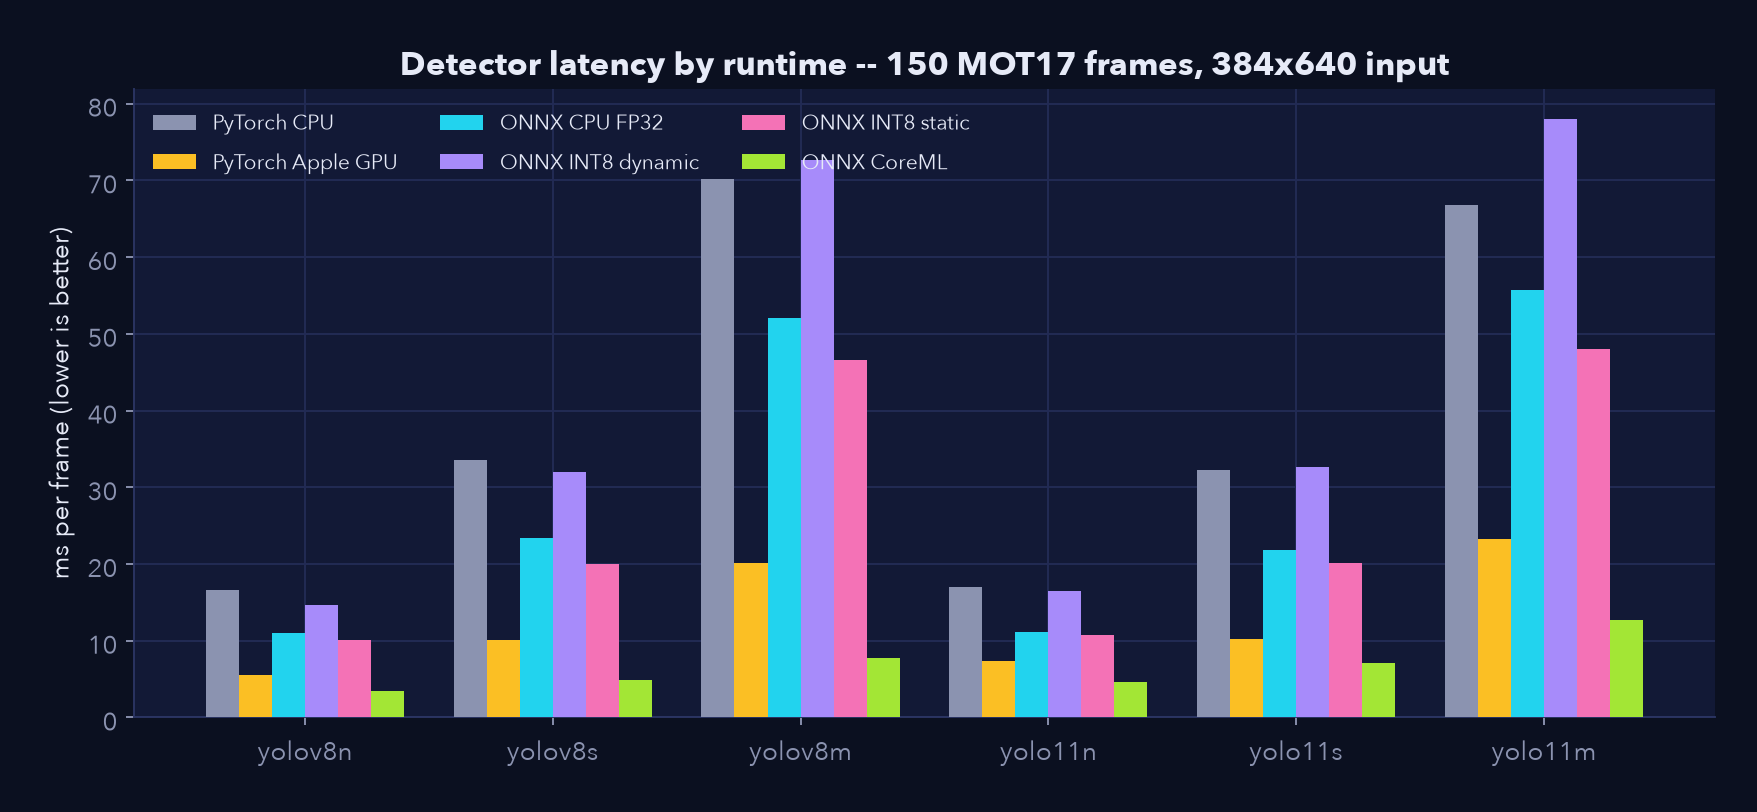

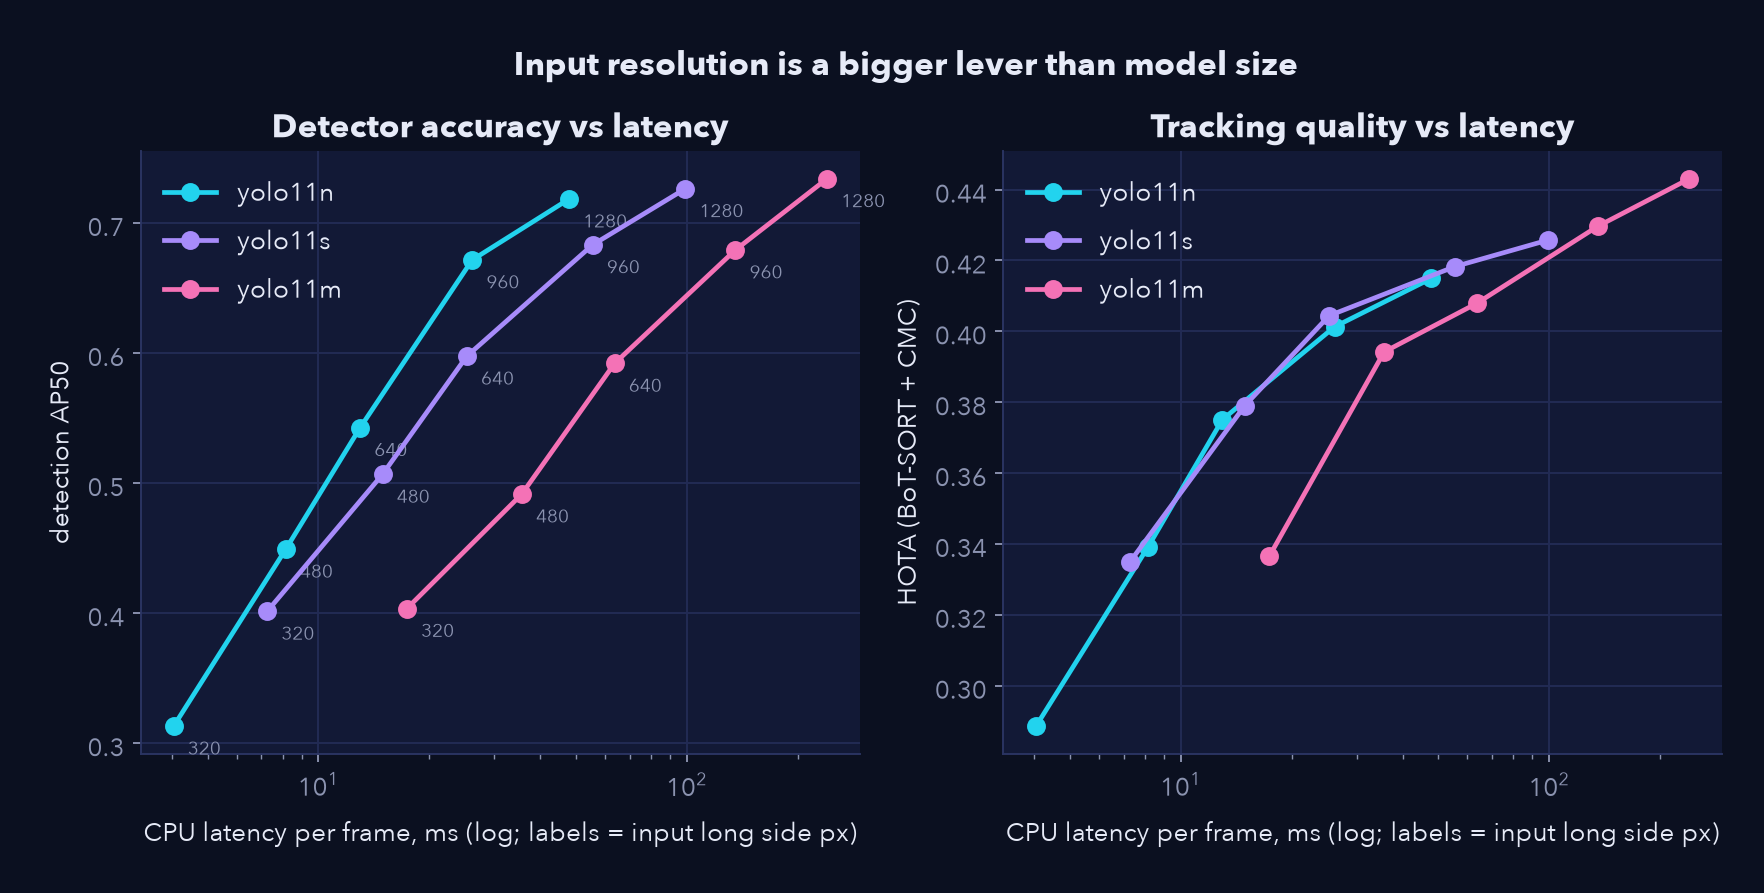

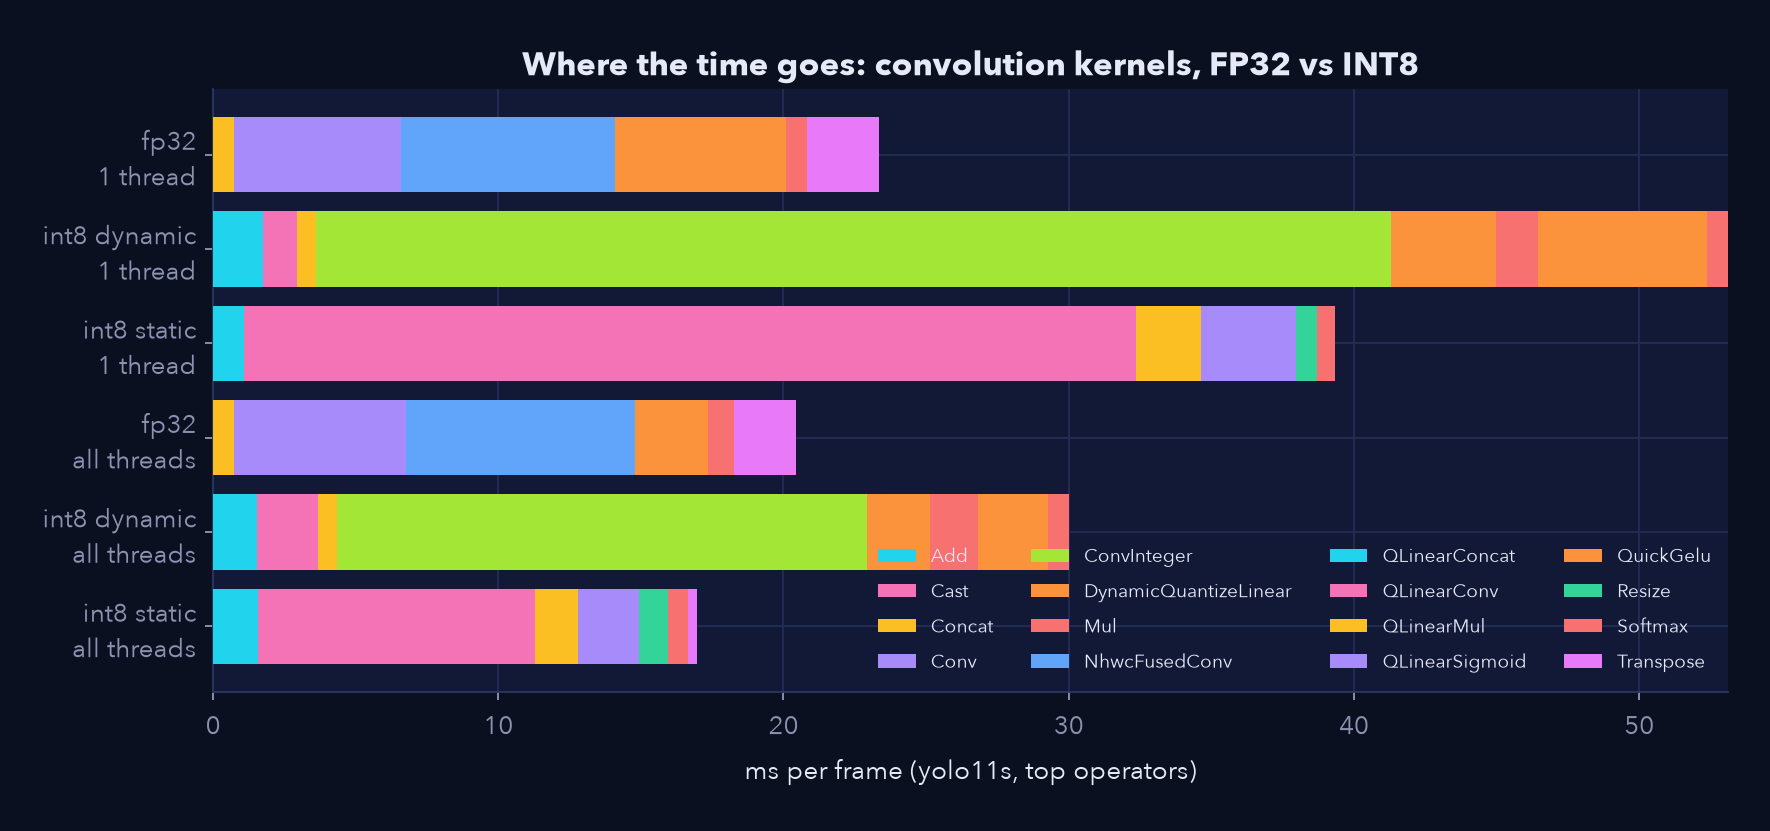

In [12]:
display(Image(ROOT / 'docs/figures/edge_latency.png', width=900))
display(Image(ROOT / 'docs/figures/edge_resolution.png', width=900))
display(Image(ROOT / 'docs/figures/edge_op_profile.png', width=900))

---
Sources: `docs/results.md`, `docs/edge.md`, `docs/methodology.md`. Regenerate figures with `make figures`.